In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from sklearn.cluster import KMeans , DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [7]:
from sklearn.datasets import load_iris

In [9]:
data = load_iris(as_frame = True ).frame

In [11]:
x = data.iloc[: , [0,1,2,3]]
y = data.iloc[:,4]

In [13]:
scaler = StandardScaler()

In [15]:
x_scaled = scaler.fit_transform(x)

In [17]:
k_means = KMeans(n_clusters = 3 , random_state=42 , n_init = 10)

In [35]:
clusters = k_means.fit_predict(x_scaled)

In [37]:
print("Cluster Labels" , clusters)
print("\n")
print("Cluster centres" , k_means.cluster_centers_)

Cluster Labels [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


Cluster centres [[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


In [39]:
## reducing four dimensions to 2 for visulization

In [41]:
from sklearn.decomposition import PCA

In [43]:
pca = PCA(n_components=2)

In [45]:
x_pca = pca.fit_transform(x_scaled)

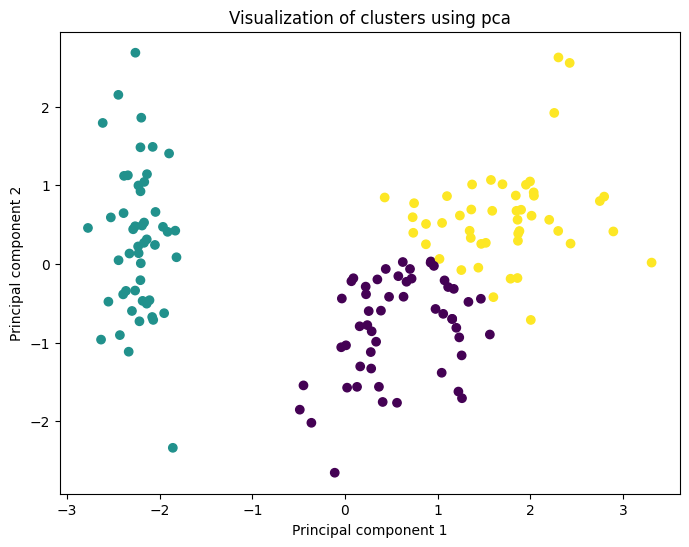

In [47]:
plt.figure(figsize=(8,6))

plt.scatter(
    x_pca[:,0],
    x_pca[:,1],
    c = clusters,
    cmap="viridis"
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Visualization of clusters using pca")
plt.show()

In [49]:
# Elbow method

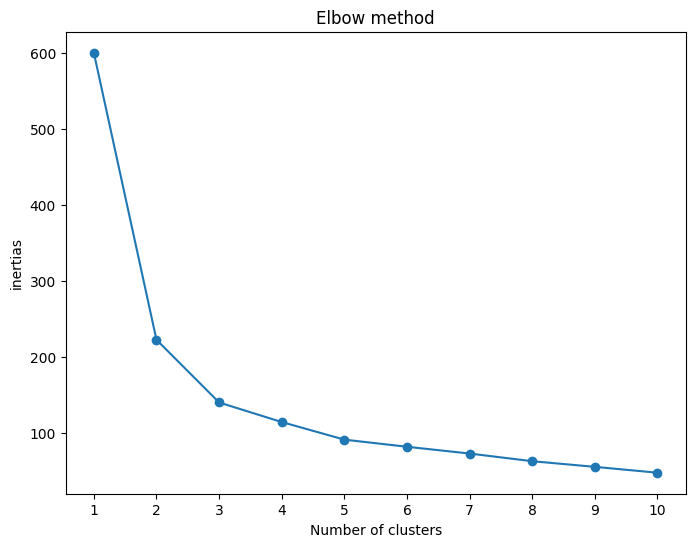

In [53]:
inertia =[]

for k in range(1,11):
    km = KMeans(n_clusters = k , random_state=42 , n_init = 10)
    km.fit(x_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8,6))
plt.plot(range(1,11) , inertia , marker='o')
plt.xlabel("Number of clusters")
plt.ylabel("inertias")
plt.title("Elbow method")
plt.xticks(range(1,11))
plt.show()

In [ ]:
z